[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/attention-explained/blob/main/notebooks/04_scaled_dot_product_attention.ipynb)

# 04 · Scaled Dot-Product Attention, by Hand

*Attention, Explained · Hamza Hentabli, Ph.D. · ~30 min*

This is the one equation at the heart of every Transformer. Here we compute it **completely by hand** on a three-word sentence — scores, scaling, softmax, weighted sum — with every intermediate number printed, then verify the result against PyTorch and *measure* why the $\sqrt{d_k}$ is there.

**Learning objectives.** By the end of this notebook you will be able to:

- compute $\text{softmax}(QK^\top/\sqrt{d_k})V$ step by step and read every intermediate matrix
- implement a numerically stable **softmax**
- verify a hand calculation against PyTorch's `scaled_dot_product_attention`
- explain, with a measurement, **why we divide by $\sqrt{d_k}$**

In [1]:
# Setup: on Google Colab this installs anything missing and clones the repo so the
# shared `attn_utils` helper is available. Running locally, install requirements.txt
# once and this cell just locates the files. No notebook needs the network after this.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("ATTN_OFFLINE", "0") == "1"   # CI sets this; everything is computed locally
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "numpy", "torch", "matplotlib", "scikit-learn"], check=True)
    if not os.path.isdir("attention-explained"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/attention-explained.git"], check=True)
    ROOT = "attention-explained"
else:
    ROOT = ".." if os.path.exists("../attn_utils.py") else "."
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import matplotlib.pyplot as plt
import attn_utils as au

au.set_docs_dir(os.path.join(ROOT, "docs"))
au.set_seed(0)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| numpy", np.__version__)


Colab: False | offline: True | numpy 2.4.6


## The formula

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) V$$

Four steps: **(1)** scores $QK^\top$ · **(2)** scale by $1/\sqrt{d_k}$ · **(3)** softmax each row · **(4)** weighted sum of $V$.

We will do all four on a 3-word sentence, printing **every** intermediate number, and then check our hand calculation against PyTorch.

## 0. The inputs

Sentence: **"I love cats"**. Each token gets a 4-dimensional embedding. To keep the arithmetic readable we choose small round numbers and simple projection matrices (in a trained model these are learned).

In [2]:
tokens = ["I", "love", "cats"]
X = np.array([[1.0, 0.0, 1.0, 0.0],    # I
              [0.0, 2.0, 0.0, 2.0],    # love
              [1.0, 1.0, 1.0, 1.0]])   # cats

W_Q = np.array([[1, 0, 1, 0],
                [0, 1, 0, 1],
                [1, 0, 0, 0],
                [0, 0, 0, 1]], dtype=float)
W_K = np.array([[0, 0, 1, 1],
                [1, 1, 0, 0],
                [0, 1, 1, 0],
                [1, 0, 0, 0]], dtype=float)
W_V = np.array([[1, 0, 0, 0],
                [0, 1, 0, 0],
                [0, 0, 2, 0],
                [0, 0, 0, 3]], dtype=float)

Q, K, V = X @ W_Q, X @ W_K, X @ W_V
for name, M in (("Q", Q), ("K", K), ("V", V)):
    print(f"{name} =")
    for t, row in zip(tokens, M):
        print(f"   {t:5s} {row}")

Q =
   I     [2. 0. 1. 0.]
   love  [0. 2. 0. 4.]
   cats  [2. 1. 1. 2.]
K =
   I     [0. 1. 2. 1.]
   love  [4. 2. 0. 0.]
   cats  [2. 2. 2. 1.]
V =
   I     [1. 0. 2. 0.]
   love  [0. 2. 0. 6.]
   cats  [1. 1. 2. 3.]


## Step 1 — Raw scores: $S = QK^\top$

Entry $S_{ij}$ is the dot product of query $i$ with key $j$: *how much does token $i$ want token $j$?* Let's write one out in full, then compute the whole matrix.

In [3]:
i, j = 0, 2   # query "I", key "cats"
terms = " + ".join(f"{a:g}×{b:g}" for a, b in zip(Q[i], K[j]))
print(f"S[{tokens[i]}, {tokens[j]}] = q_{tokens[i]} · k_{tokens[j]} = {terms} = {Q[i] @ K[j]:g}")

S = Q @ K.T
print("\nS = Q Kᵀ  (rows = queries, columns = keys)")
print("          " + "".join(f"{t:>8s}" for t in tokens))
for t, row in zip(tokens, S):
    print(f"   {t:6s}" + "".join(f"{v:8.2f}" for v in row))

S[I, cats] = q_I · k_cats = 2×2 + 0×2 + 1×2 + 0×1 = 6

S = Q Kᵀ  (rows = queries, columns = keys)
                 I    love    cats
   I         2.00    8.00    6.00
   love      6.00    4.00    8.00
   cats      5.00   10.00   10.00


## Step 2 — Scale: $S / \sqrt{d_k}$

Here $d_k = 4$, so we divide by $\sqrt{4} = 2$. (Section 6 shows *why* this matters.)

In [4]:
d_k = K.shape[1]
S_scaled = S / np.sqrt(d_k)
print(f"d_k = {d_k},  sqrt(d_k) = {np.sqrt(d_k):g}")
print("          " + "".join(f"{t:>8s}" for t in tokens))
for t, row in zip(tokens, S_scaled):
    print(f"   {t:6s}" + "".join(f"{v:8.2f}" for v in row))

d_k = 4,  sqrt(d_k) = 2
                 I    love    cats
   I         1.00    4.00    3.00
   love      3.00    2.00    4.00
   cats      2.50    5.00    5.00


## Step 3 — Softmax each row

For each query row: subtract the row maximum (for numerical safety — it does not change the result), exponentiate, divide by the row sum.

$$\text{softmax}(s)_j = \frac{e^{s_j}}{\sum_m e^{s_m}}$$

In [5]:
A = np.zeros_like(S_scaled)
for r, t in enumerate(tokens):
    row = S_scaled[r]
    shifted = row - row.max()
    e = np.exp(shifted)
    A[r] = e / e.sum()
    print(f"query '{t}':")
    print(f"   scaled scores   {row}")
    print(f"   minus max       {shifted}")
    print(f"   exp             {e}")
    print(f"   sum of exp      {e.sum():.4f}")
    print(f"   weights         {A[r]}   (sum = {A[r].sum():.4f})\n")

query 'I':
   scaled scores   [1. 4. 3.]
   minus max       [-3.  0. -1.]
   exp             [0.05  1.    0.368]
   sum of exp      1.4177
   weights         [0.035 0.705 0.259]   (sum = 1.0000)

query 'love':
   scaled scores   [3. 2. 4.]
   minus max       [-1. -2.  0.]
   exp             [0.368 0.135 1.   ]
   sum of exp      1.5032
   weights         [0.245 0.09  0.665]   (sum = 1.0000)

query 'cats':
   scaled scores   [2.5 5.  5. ]
   minus max       [-2.5  0.   0. ]
   exp             [0.082 1.    1.   ]
   sum of exp      2.0821
   weights         [0.039 0.48  0.48 ]   (sum = 1.0000)



## Step 4 — Weighted sum of values: $Z = AV$

Output for query $i$ is $\sum_j A_{ij} v_j$. Again, one row written out, then the full matrix.

In [6]:
r = 0
parts = " + ".join(f"{A[r, j]:.3f}·{V[j]}" for j in range(len(tokens)))
print(f"z_{tokens[r]} = {parts}")
print(f"     = {A[r] @ V}\n")

Z = A @ V
for t, row in zip(tokens, Z):
    print(f"z_{t:5s} = {row}")

z_I = 0.035·[1. 0. 2. 0.] + 0.705·[0. 2. 0. 6.] + 0.259·[1. 1. 2. 3.]
     = [0.295 1.67  0.589 5.011]

z_I     = [0.295 1.67  0.589 5.011]
z_love  = [0.91  0.845 1.82  2.536]
z_cats  = [0.52  1.441 1.039 4.323]


## 5. Check against the library implementations

Our hand-rolled numbers should match the course helper `au.scaled_dot_product_attention` and PyTorch's built-in `F.scaled_dot_product_attention` (the fused kernel used by real models).

matches helper : True True
matches PyTorch: True


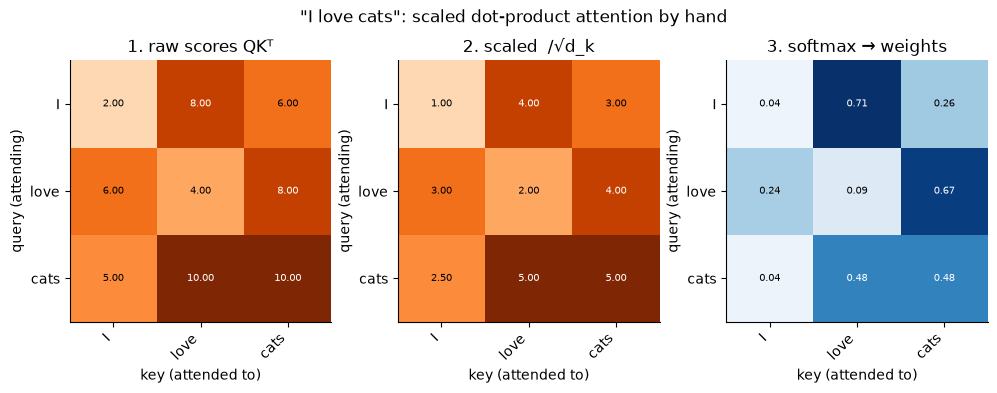

In [7]:
import torch
import torch.nn.functional as F

Z_helper, A_helper = au.scaled_dot_product_attention(Q, K, V)
Z_torch = F.scaled_dot_product_attention(torch.tensor(Q)[None], torch.tensor(K)[None], torch.tensor(V)[None])[0].numpy()
print("matches helper :", np.allclose(Z, Z_helper), np.allclose(A, A_helper))
print("matches PyTorch:", np.allclose(Z, Z_torch))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, M, title in zip(axes, (S, S_scaled, A), ("1. raw scores QKᵀ", "2. scaled  /√d_k", "3. softmax → weights")):
    au.plot_attention(M, tokens, tokens, ax=ax, title=title, cmap="Blues" if M is A else "Oranges")
fig.suptitle('"I love cats": scaled dot-product attention by hand', y=1.03)
au.save_fig(fig, "04_attention_by_hand.png")
plt.show()

## 6. Why divide by $\sqrt{d_k}$?

If the components of $q$ and $k$ are independent with mean 0 and variance 1, then $q\cdot k = \sum_{m=1}^{d_k} q_m k_m$ has variance $d_k$: its typical size grows like $\sqrt{d_k}$. Big scores push the softmax into **saturation** — one weight ≈ 1, the rest ≈ 0 — where gradients almost vanish and learning stalls. Dividing by $\sqrt{d_k}$ brings the variance back to 1, whatever the dimension.

Let's *measure* it with random vectors.

 d_k   std(q·k)  std(q·k/√d)   mean max-weight raw   scaled
    4      2.01        1.00                 0.496    0.304
   16      4.03        1.01                 0.726    0.319
   64      7.86        0.98                 0.856    0.315
  256     15.91        0.99                 0.931    0.318
 1024     32.02        1.00                 0.968    0.319


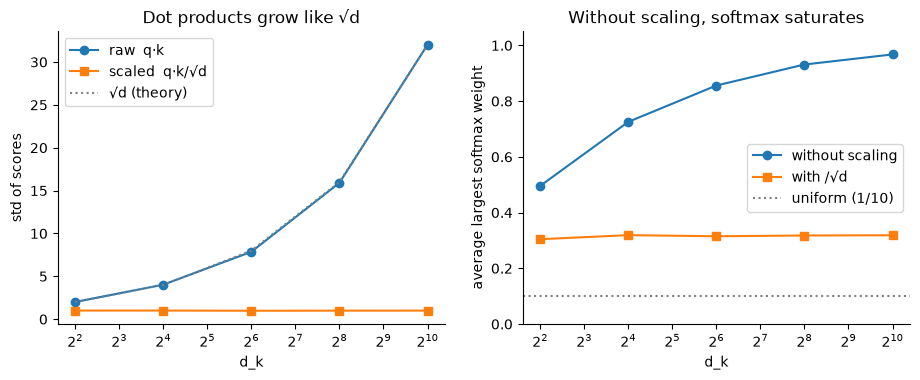

In [8]:
rng = np.random.default_rng(0)
dims = [4, 16, 64, 256, 1024]
n_keys, trials = 10, 2000
std_raw, std_scaled, maxw_raw, maxw_scaled = [], [], [], []
for d in dims:
    q = rng.normal(size=(trials, 1, d)); k = rng.normal(size=(trials, n_keys, d))
    s = (q * k).sum(-1)                          # (trials, n_keys) raw dot products
    std_raw.append(s.std()); std_scaled.append((s / np.sqrt(d)).std())
    maxw_raw.append(au.softmax(s, -1).max(-1).mean())
    maxw_scaled.append(au.softmax(s / np.sqrt(d), -1).max(-1).mean())

print(" d_k   std(q·k)  std(q·k/√d)   mean max-weight raw   scaled")
for row in zip(dims, std_raw, std_scaled, maxw_raw, maxw_scaled):
    print("{:5d}  {:8.2f}  {:10.2f}   {:19.3f}   {:6.3f}".format(*row))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(dims, std_raw, "o-", label="raw  q·k"); axes[0].plot(dims, std_scaled, "s-", label="scaled  q·k/√d")
axes[0].plot(dims, np.sqrt(dims), ":", color="grey", label="√d (theory)")
axes[0].set_xscale("log", base=2); axes[0].set_xlabel("d_k"); axes[0].set_ylabel("std of scores"); axes[0].legend()
axes[0].set_title("Dot products grow like √d")
axes[1].plot(dims, maxw_raw, "o-", label="without scaling"); axes[1].plot(dims, maxw_scaled, "s-", label="with /√d")
axes[1].axhline(1 / n_keys, color="grey", ls=":", label="uniform (1/10)")
axes[1].set_xscale("log", base=2); axes[1].set_ylim(0, 1.05); axes[1].set_xlabel("d_k")
axes[1].set_ylabel("average largest softmax weight"); axes[1].legend(); axes[1].set_title("Without scaling, softmax saturates")
au.save_fig(fig, "04_why_sqrt_d.png")
plt.show()

Without scaling, the largest weight creeps toward 1 as $d_k$ grows (the softmax becomes a hard *argmax*); with scaling it stays put at every dimension. That single division is why the formula has a $\sqrt{d_k}$ in it.

## Key takeaways

- Scaled dot-product attention = **scores → scale → softmax → weighted sum**.
- Every row of the weight matrix is a probability distribution over the keys.
- Dividing by $\sqrt{d_k}$ keeps score variance ≈ 1 so the softmax does not saturate in high dimensions.

### ✏️ Exercise 1

Recompute the weights for query `love` **without** the $\sqrt{d_k}$ scaling. Is the distribution sharper or flatter?

<details>
<summary><b>Show solution</b></summary>

```python
print("scaled  :", A[1])
print("unscaled:", au.softmax(S[1]))
```

Unscaled scores are twice as large, so the softmax is sharper.

</details>

### ✏️ Exercise 2

Add a 4th token `"too"` with embedding `[0, 1, 0, 1]` and recompute the full 4×4 attention matrix with `au.scaled_dot_product_attention`.

<details>
<summary><b>Show solution</b></summary>

```python
X4 = np.vstack([X, [0, 1, 0, 1]])
Z4, A4 = au.scaled_dot_product_attention(X4 @ W_Q, X4 @ W_K, X4 @ W_V)
print(A4)
```



</details>

### ✏️ Exercise 3

Show numerically that adding a constant to every score in a row does not change the softmax (this is why subtracting the max is safe).

<details>
<summary><b>Show solution</b></summary>

```python
row = S_scaled[0]
print(np.allclose(au.softmax(row), au.softmax(row + 100)))
```



</details>